# Filler Strategy Lab
**A quantitative comparison of decision strategies in a two-player territory-capture game**

This notebook contains the complete Python model, verification checks, experimental design and analysis. Run all cells from the repository directory. Python 3.10 or newer, pandas and matplotlib are required; Node.js is optional for the browser comparison. The accompanying `games.csv` contains the original results.

## 1. Research objective and rules

Does incorporating future territory and an opponent's responses improve performance relative to maximizing immediate gains? Two players start in opposite corners of a 7 × 8 grid with six colors. Players alternate selecting a color different from both current colors and capture all connected, adjacent, unclaimed tiles of that color. Owned tiles cannot be stolen. The player with more tiles after the board is filled wins.

**Modeling assumptions:** horizontal/vertical adjacency only; distinct starting colors; zero-gain moves are permitted. A draw is declared after 12 consecutive zero-gain moves, even when one player owns more tiles. The cutoff is a simulation safeguard, not a verified rule of the original game.

## 2. Board representation and game mechanics

Let $S_1$ and $S_2$ be the sets of tiles owned by each player. A state contains these territories, their current colors, the player to move, and the consecutive noncapture count. To capture a color, repeatedly add neighboring unclaimed tiles of that color until no more tiles can be added.

The implementation stores tile sets as integers: bit $i$ indicates whether row-major tile $i$ belongs to the set. This compact representation implements set union, intersection and adjacency while preserving the mathematical rules. The seeded board generator excludes horizontally or vertically adjacent identical colors and reproduces the browser's board sequence.

In [1]:
"""Reference implementation. Bit i denotes row-major tile i; colors 0..5.

Rules: orthogonal adjacency, transitive captures, immutable neutral colors,
no stealing, current and opponent colors unavailable. Noncapturing moves are
allowed. A 12-consecutive-noncapture draw cutoff is a documented simulation rule.
"""
from dataclasses import dataclass
from random import Random

COLORS = 'BRGYKP'
STALL_LIMIT = 12
WEIGHTS = (10, 2, 4, 1)

@dataclass(frozen=True, slots=True)
class Board:
    rows: int
    cols: int
    colors: tuple[int, ...]
    masks: tuple[int, ...] = ()
    full: int = 0
    left: int = 0
    right: int = 0

    def __post_init__(self):
        if not (2 <= self.rows <= 10 and 2 <= self.cols <= 10):
            raise ValueError('Board dimensions must be between 2 and 10')
        colors = tuple(self.colors)
        if len(colors) != self.rows * self.cols or any(not isinstance(c, int) or not 0 <= c < 6 for c in colors):
            raise ValueError('Expected rows × cols colors in 0..5')
        if colors[(self.rows - 1) * self.cols] == colors[self.cols - 1]:
            raise ValueError('Starting corner colors must differ')
        object.__setattr__(self, 'colors', colors)
        object.__setattr__(self, 'masks', tuple(sum(1 << i for i, c in enumerate(colors) if c == k) for k in range(6)))
        object.__setattr__(self, 'full', (1 << len(colors)) - 1)
        object.__setattr__(self, 'left', sum(1 << (r*self.cols) for r in range(self.rows)))
        object.__setattr__(self, 'right', self.left << (self.cols - 1))

    def neighbors(self, bits):
        return (((bits & ~self.left) >> 1) | ((bits & ~self.right) << 1) |
                (bits >> self.cols) | (bits << self.cols)) & self.full

@dataclass(frozen=True, slots=True)
class State:
    p0: int
    p1: int
    c0: int
    c1: int
    turn: int = 0
    stalls: int = 0

    @property
    def owned(self):
        return self.p0, self.p1

    @property
    def colors(self):
        return self.c0, self.c1


def generate_board(rows=7, cols=8, seed=1):
    """Portable xorshift32 generator; excludes left/up colors and matching corners."""
    if not (2 <= rows <= 10 and 2 <= cols <= 10):
        raise ValueError('Board dimensions must be between 2 and 10')
    x = int(seed) & 0xffffffff or 0x9e3779b9
    values = []
    for i in range(rows*cols):
        r, c = divmod(i, cols)
        banned = set()
        if r: banned.add(values[i-cols])
        if c: banned.add(values[i-1])
        if i == (rows-1)*cols: banned.add(values[cols-1])
        choices = [k for k in range(6) if k not in banned]
        x ^= (x << 13) & 0xffffffff
        x ^= x >> 17
        x ^= (x << 5) & 0xffffffff
        x &= 0xffffffff
        values.append(choices[x % len(choices)])
    return Board(rows, cols, tuple(values))


def new_game(board, first=0):
    if first not in (0,1): raise ValueError('Invalid first player')
    a, b = (board.rows - 1) * board.cols, board.cols - 1
    return State(1 << a, 1 << b, board.colors[a], board.colors[b], first)


def score(state):
    return state.p0.bit_count(), state.p1.bit_count()


def terminal(board, state):
    return (state.p0 | state.p1) == board.full or state.stalls >= STALL_LIMIT


def legal_moves(board, state):
    return () if terminal(board, state) else tuple(c for c in range(6) if c not in state.colors)


def captured(board, state, color, player=None):
    """Fixed-point flood fill of neutral tiles of the selected color."""
    player = state.turn if player is None else player
    own = state.owned[player]
    remaining = board.masks[color] & ~(state.p0 | state.p1)
    hit = board.neighbors(own) & remaining
    result = hit
    while hit:
        hit = board.neighbors(hit) & remaining & ~result
        result |= hit
    return result


def apply_move(board, state, color):
    if color not in legal_moves(board, state):
        raise ValueError('Illegal move')
    add = captured(board, state, color)
    stalls = 0 if add else state.stalls + 1
    if state.turn == 0:
        return State(state.p0 | add, state.p1, color, state.c1, 1, stalls)
    return State(state.p0, state.p1 | add, state.c0, color, 0, stalls)

## 3. Quantitative evaluation of a position

For nonterminal states, the relative advantage of Player 1 is measured using

$$H(s)=10D(s)+2F(s)+4R(s)+M(s).$$

Each component is the difference between the players: $D$ is the tile count, $F$ is the number of bordering neutral tiles, $R$ counts neutral tiles strictly closer to each territory along paths through unclaimed cells, and $M$ is the maximum immediate capture available under the current legal colors. Tied or unreachable neutral tiles contribute zero to $R$. The weights are illustrative, not fitted parameters. A positive score favors Player 1.

At a completed game, a win or loss receives a utility of +10,000 or −10,000 plus the final tile difference. Ties and stalled games receive zero. This makes a completed win or loss dominate intermediate evaluations.

In [2]:
def potential(board, state):
    """Difference in neutral cells closer to P0 vs P1 by obstacle-aware BFS.
    Both searches travel through neutral cells only; tied/unreachable cells get 0.
    """
    neutral = board.full & ~(state.p0 | state.p1)
    f0, f1 = state.p0, state.p1
    seen0 = seen1 = assigned = 0
    value = 0
    while f0 or f1:
        f0 = board.neighbors(f0) & neutral & ~seen0
        f1 = board.neighbors(f1) & neutral & ~seen1
        seen0 |= f0; seen1 |= f1
        a, b = f0 & ~assigned, f1 & ~assigned
        value += (a & ~b).bit_count() - (b & ~a).bit_count()
        assigned |= a | b
        if assigned == neutral: break
    return value


def features(board, state):
    a, b = score(state)
    neutral = board.full & ~(state.p0 | state.p1)
    frontier = (board.neighbors(state.p0) & neutral).bit_count() - (board.neighbors(state.p1) & neutral).bit_count()
    moves = [c for c in range(6) if c not in state.colors]
    best = [max((captured(board, state, c, p).bit_count() for c in moves), default=0) for p in (0,1)]
    return a-b, frontier, potential(board, state), best[0]-best[1]


def evaluate(board, state, weights=WEIGHTS):
    if terminal(board, state):
        if (state.p0 | state.p1) != board.full: return 0
        a,b = score(state)
        # Terminal wins/losses dominate any nonterminal heuristic on supported boards.
        return (10000 if a>b else -10000 if b>a else 0) + (a-b)
    return sum(w*f for w,f in zip(weights, features(board,state)))

## 4. Competing decision strategies

- **Random:** uniformly sample an available color.
- **Greedy:** maximize immediate tile gain.
- **Heuristic:** maximize the weighted evaluation after one move (minimize for Player 2).
- **Minimax:** evaluate possible sequences of alternating moves, assuming the opponent makes favorable choices. Depth counts individual turns, not rounds. Alpha–beta pruning avoids evaluating choices that cannot improve the decision at the selected depth.

The same decision function implements all four strategies, using immediate gain and then color index to break ties in move ordering.

In [3]:
def choose_move(board, state, strategy='minimax', depth=4, rng=None, prune=True):
    """Return a decision dictionary. Depth is measured in individual turns.
    All search values are from P0's perspective. Tie order is gain then color.
    No transposition cache; prune=False provides a verification baseline.
    """
    if strategy not in ('random','greedy','heuristic','minimax'):
        raise ValueError('Unknown strategy')
    moves = legal_moves(board,state)
    if not moves: return {'color':None,'value':evaluate(board,state),'nodes':0,'cutoffs':0}
    depth = int(depth)
    if not 1 <= depth <= 8: raise ValueError('Depth must be 1..8')
    def ordered(s):
        return sorted(legal_moves(board,s), key=lambda c:(-captured(board,s,c).bit_count(),c))
    if strategy == 'random':
        color = (rng or Random()).choice(moves)
        return {'color':color,'value':None,'nodes':0,'cutoffs':0}
    if strategy == 'greedy':
        color = ordered(state)[0]
        return {'color':color,'value':None,'nodes':0,'cutoffs':0}
    if strategy == 'heuristic': depth = 1
    nodes = cutoffs = 0
    def search(s,d,alpha,beta):
        nonlocal nodes,cutoffs
        nodes += 1
        if d == 0 or terminal(board,s): return evaluate(board,s)
        maximizing = s.turn == 0
        value = -float('inf') if maximizing else float('inf')
        for c in ordered(s):
            v = search(apply_move(board,s,c),d-1,alpha,beta)
            if maximizing: value=max(value,v); alpha=max(alpha,value)
            else: value=min(value,v); beta=min(beta,value)
            if prune and alpha >= beta:
                cutoffs += 1
                break
        return value
    maximizing = state.turn == 0
    best = -float('inf') if maximizing else float('inf')
    color = None
    alpha,beta = -float('inf'),float('inf')
    for c in ordered(state):
        value = search(apply_move(board,state,c),depth-1,alpha,beta)
        if color is None or (value>best if maximizing else value<best):
            best,color=value,c
        if maximizing: alpha=max(alpha,best)
        else: beta=min(beta,best)
    return {'color':color,'value':best,'nodes':nodes,'cutoffs':cutoffs}

## 5. Model verification

These checks preserve the original coverage: boundary behavior, connected captures, invalid moves, the stall rule, territory invariants, an independent coordinate-based capture implementation, and agreement between pruned and exhaustive finite-depth searches. The final check compares the Python model against the JavaScript implementation embedded in the interactive game. Node.js is only needed for that check.

In [4]:
import random, json, subprocess, shutil
from pathlib import Path
from collections import deque
from contextlib import contextmanager

@contextmanager
def expect_value_error():
    try:
        yield
    except ValueError:
        return
    raise AssertionError('Expected ValueError')

def slow_capture(b,s,c):
    """Independent coordinate BFS oracle; no bit-shift logic."""
    owned={i for i in range(b.rows*b.cols) if s.owned[s.turn] >> i & 1}
    other={i for i in range(b.rows*b.cols) if s.owned[1-s.turn] >> i & 1}
    q=deque(owned); seen=set(owned); result=set()
    while q:
        i=q.popleft(); r,col=divmod(i,b.cols)
        for x,y in [(r-1,col),(r+1,col),(r,col-1),(r,col+1)]:
            if 0<=x<b.rows and 0<=y<b.cols:
                j=x*b.cols+y
                if j not in seen and j not in other and b.colors[j]==c:
                    seen.add(j); result.add(j); q.append(j)
    return sum(1<<i for i in result)


def test_no_wraparound():
    b=generate_board(3,4,1)
    assert b.neighbors(1<<3)==(1<<2)|(1<<7)
    assert b.neighbors(1<<4)==(1<<0)|(1<<5)|(1<<8)


def test_connected_capture_and_no_stealing():
    b=Board(3,3,(2,2,4,2,1,3,0,2,3));s=new_game(b)
    assert captured(b,s,2).bit_count()==4
    t=apply_move(b,s,2)
    assert score(t)==(5,1) and t.p1==s.p1 and t.turn==1
    assert s.p0.bit_count()==1
    with expect_value_error(): apply_move(b,t,2)
    with expect_value_error(): apply_move(b,t,4)


def test_stall_rule_and_terminal():
    b=generate_board(2,2,5);s=new_game(b)
    for i in range(12):
        c=next(c for c in legal_moves(b,s) if not captured(b,s,c))
        s=apply_move(b,s,c)
    assert terminal(b,s) and not legal_moves(b,s) and score(s)==(1,1)
    assert evaluate(b,s)==0
    b=generate_board(3,3,1); s=State(7,1<<8,0,1,0,STALL_LIMIT)
    assert score(s)==(3,1) and terminal(b,s) and evaluate(b,s)==0


def test_validation():
    with expect_value_error(): Board(2,2,(0,1,1,0))
    with expect_value_error(): generate_board(1,1)


def test_random_games_invariants_and_bfs(size):
    rng=random.Random(11)
    for seed in range(12):
        b=generate_board(*size,seed);s=new_game(b,seed%2)
        for i in range(3000):
            if terminal(b,s):break
            for c in legal_moves(b,s): assert captured(b,s,c)==slow_capture(b,s,c)
            c=rng.choice(legal_moves(b,s));t=apply_move(b,s,c)
            assert not(t.p0&t.p1) and (t.p0|t.p1)&~b.full==0
            assert s.p0&t.p0==s.p0 and s.p1&t.p1==s.p1
            assert t.owned[1-s.turn]==s.owned[1-s.turn] and t.turn==1-s.turn
            assert t.colors[0]!=t.colors[1]
            s=t
        else: raise AssertionError('game failed to terminate')


def test_pruned_equals_exhaustive(seed):
    b=generate_board(5,5,seed);s=new_game(b,seed%2)
    for _ in range(3):s=apply_move(b,s,choose_move(b,s,'greedy')['color'])
    a=choose_move(b,s,depth=4);z=choose_move(b,s,depth=4,prune=False)
    assert (a['color'],a['value'])==(z['color'],z['value'])
    assert a['nodes']<=z['nodes']


def test_terminal_win_dominates():
    b=generate_board(2,2,4); s=State(7,8,0,1)
    assert terminal(b,s) and evaluate(b,s)==10002


def test_js_python_parity():
    html = Path('index.html').read_text(encoding='utf-8')
    engine = html.split('<script id="engine-code">', 1)[1].split('</script>', 1)[0]
    parity = "const F=module.exports;const results=[];\nfor(let seed=0;seed<12;seed++){\n const b=F.generate(7,8,seed);let s=F.newGame(b,seed%2);const steps=[];\n for(let i=0;i<8;i++){const a=F.choose(b,s,'minimax',3);steps.push([F.score(s),F.features(b,s),F.legal(b,s),F.legal(b,s).map(c=>F.count(F.captured(b,s,c))),a]);s=F.apply(b,s,a.color);}\n results.push([b.colors,steps]);\n}\nconsole.log(JSON.stringify(results));\n"
    js = subprocess.run(['node', '-e', engine + '\n' + parity], capture_output=True, text=True, check=True)
    actual=json.loads(js.stdout)
    expected=[]
    for seed in range(12):
        b=generate_board(7,8,seed);s=new_game(b,seed%2)
        steps=[]
        for _ in range(8):
            a=choose_move(b,s,'minimax',3)
            steps.append([list(score(s)),list(features(b,s)),list(legal_moves(b,s)),[captured(b,s,c).bit_count() for c in legal_moves(b,s)],a])
            s=apply_move(b,s,a['color'])
        expected.append([list(b.colors),steps])
    assert actual==expected

In [5]:
checks = [test_no_wraparound, test_connected_capture_and_no_stealing,
          test_stall_rule_and_terminal, test_validation, test_terminal_win_dominates]
for check in checks:
    check()
for size in [(2, 2), (3, 4), (7, 8), (10, 10)]:
    test_random_games_invariants_and_bfs(size)
for seed in range(12):
    test_pruned_equals_exhaustive(seed)
print('21 Python checks passed.')
if shutil.which('node') and Path('index.html').exists():
    test_js_python_parity()
    print('Browser/Python agreement check passed (22 checks total).')
else:
    print('Optional browser/Python agreement check skipped: Node.js or index.html unavailable.')

21 Python checks passed.
Browser/Python agreement check passed (22 checks total).


## 6. Simulation design

The benchmark crosses four matchups, 64 board seeds (1001–1064), two corner assignments and two starting players, for 1,024 games. Each strategy plays each corner and moves first equally often on every board. A separate seeded random generator controls random strategy choices. The game-level outcome is +1 for an A win, 0 for a draw and −1 for a B win, with the stall cutoff applied before comparing scores.

The next cells rerun the entire experiment without overwriting the original dataset, then check every regenerated field except execution time against `games.csv`.

In [6]:
import time
import pandas as pd

MATCHUPS=[('greedy','random'),('heuristic','greedy'),('minimax:2','greedy'),('minimax:4','minimax:2')]

def play(task):
    a,z,seed,swap,first=task
    b=generate_board(7,8,seed);s=new_game(b,first)
    players=[a,z] if not swap else [z,a]
    rng=random.Random(seed*100+swap*2+first)
    nodes=[0,0];moves=[0,0];cutoffs=[0,0];turns=0
    start=time.perf_counter()
    while not terminal(b,s):
        p=s.turn; strategy,_,depth=players[p].partition(':')
        choice=choose_move(b,s,strategy,int(depth or 1),rng)
        nodes[p]+=choice['nodes'];cutoffs[p]+=choice['cutoffs'];moves[p]+=1
        s=apply_move(b,s,choice['color']);turns+=1
    sa,sz=score(s);i=1 if swap else 0
    if swap:sa,sz=sz,sa
    outcome=0 if s.stalls>=STALL_LIMIT else (1 if sa>sz else -1 if sa<sz else 0)
    return dict(strategy_a=a,strategy_b=z,seed=seed,a_corner='top-right' if swap else 'bottom-left',a_first=(first==i),a_score=sa,b_score=sz,margin=sa-sz,outcome=outcome,turns=turns,stall=s.stalls>=STALL_LIMIT,a_nodes=nodes[i],a_cutoffs=cutoffs[i],a_moves=moves[i],elapsed_ms=round((time.perf_counter()-start)*1000,3))

In [7]:
tasks = [(a, b, seed, swap, first)
         for a, b in MATCHUPS
         for seed in range(1001, 1065)
         for swap in (0, 1)
         for first in (0, 1)]
games = pd.DataFrame([play(task) for task in tasks])
original = pd.read_csv('games.csv')
columns = [c for c in original.columns if c != 'elapsed_ms']
pd.testing.assert_frame_equal(games[columns], original[columns])
print(f'Reproduced all {len(games):,} game records, excluding execution time.')

Reproduced all 1,024 game records, excluding execution time.


## 7. Results

Report win/draw/loss counts, win rate, average raw tile margin and stalled games. Raw tile margin is not the same as game outcome: a stalled game is a draw even if the tile counts differ. The four games on each board are related observations, so these are descriptive statistics rather than independent-sample estimates.

In [8]:
summary = (games.groupby(['strategy_a', 'strategy_b'], sort=False)
           .agg(games=('outcome', 'size'),
                wins=('outcome', lambda x: (x == 1).sum()),
                draws=('outcome', lambda x: (x == 0).sum()),
                losses=('outcome', lambda x: (x == -1).sum()),
                mean_margin=('margin', 'mean'),
                stalled=('stall', 'sum')).reset_index())
summary['win_rate_pct'] = 100 * summary['wins'] / summary['games']
summary[['strategy_a', 'strategy_b', 'games', 'wins', 'draws', 'losses',
         'win_rate_pct', 'mean_margin', 'stalled']].round(2)

strategy_a,strategy_b,games,wins,draws,losses,win_rate_pct,mean_margin,stalled
greedy,random,256,245,11,0,95.70,29.87,11
heuristic,greedy,256,180,49,27,70.31,4.58,19
minimax:2,greedy,256,211,33,12,82.42,5.95,13
minimax:4,minimax:2,256,82,140,34,32.03,2.46,97


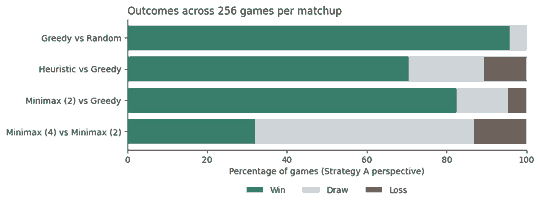

In [9]:
import matplotlib.pyplot as plt

labels = ['Greedy vs Random', 'Heuristic vs Greedy',
          'Minimax (2) vs Greedy', 'Minimax (4) vs Minimax (2)']
fig, ax = plt.subplots(figsize=(9, 3.6))
left = pd.Series(0.0, index=summary.index)
for column, label, color in [('wins', 'Win', '#387e6b'),
                             ('draws', 'Draw', '#b1b7c1'),
                             ('losses', 'Loss', '#b55b58')]:
    pct = 100 * summary[column] / summary['games']
    ax.barh(labels, pct, left=left, label=label, color=color)
    left += pct
ax.set_xlim(0, 100)
ax.set_xlabel('Percentage of games (Strategy A perspective)')
ax.set_title('Outcomes across 256 games per matchup', loc='left')
ax.invert_yaxis()
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.22), frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

## 8. Interpretation and limitations

The greedy strategy wins 95.7% against random selection. Incorporating the position evaluation increases performance against greedy to 70.3%, and two-turn minimax wins 82.4% against greedy. Four-turn minimax wins more often than it loses against two-turn minimax (82 wins versus 34 losses), but 140 games end in draws; 97 of these reach the stall cutoff. Deeper search therefore does not guarantee a better result.

These findings depend on the seeded board distribution, fixed heuristic coefficients, and project-specific stall rule. They do not establish performance on the original GamePigeon app or against human opponents. The weights were not fitted or tuned. Potential extensions include tuning coefficients on training boards and evaluating on held-out boards, varying the stall rule, and analyzing first-player advantage. The interactive demonstration is provided in `index.html`.